In [1]:
%load_ext autoreload
%autoreload 2
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import sys
import numpy as np
from IPython.display import display

code_path = "../src" # linux
sys.path.append(code_path)
sys.path.append(code_path+"/src")

import utilities as util
from anony_interface import ANInference
from xai_vad_zsac_interface import ADXAIDetector
from xai_vad_zsam_interface import GRAD4VAD_XAI_PPA
from xai_vad_zsad_interface import ADXAIVLMInference
from config import config as cfg

%matplotlib inline

# Installation

In [2]:
# !git clone https://github.com/muleina/XAVAD.git

In [3]:
# !pip install -e XAVAD/

# Load Models and Configs

In [4]:
# Configs
fps = 5 # increase for better accuracy, decrease for speed
video_chunck_freq = 16  # XAI eval runs every 16 video frames 

## Load MASKING ZSAN: Anonymization

In [5]:
# ZSAN interface Config
zsan_kwargs = {'anony_method': 'mask',
                'detector_name': 'body__yolo',
                'detector_version': 'yolov8m-seg',
                'detector_imgsz': None,
                'detection_thr': 0.15,
                'detection_classes': [0], # person,
                "kwargs_anony_method": {"color":"#190fd4"}
                }
ANObj = ANInference(**zsan_kwargs)

init_anonymizer...
{'detector_name': 'body__yolo', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#190fd4', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.15, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.15, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  yolov8m-seg
{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7efad0cdd580>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#190fd4', 'preprocessors_list': [], 'postprocessors_list': []}}


## Load XAI ZSAC: CLIP

In [6]:
# XAI ZSAC interface Config
zsac_kwargs = {'clip_modelname': 'ViT-L/14',
            'pooling_method': 'max',
            'prompt_concept_json_filepath': '../src/model/clip/llmv2_custom-concept.json',
            'prompt_feature_np_filepath': '../src/model/clip/anml_class_prompt_clip_features_norm_llmv2_custom_ViTL14.npy',
            'similarity_metric': 'cosine_softmax',
            'isreturn_max_indices': True
            }

ADXAIObj = ADXAIDetector(device="cuda", **zsac_kwargs)

xai_class_name_mapper = dict(zip(ADXAIObj.clip4vadObj.anml_class_names, range(len(ADXAIObj.clip4vadObj.anml_class_names))))

CLIP4VAD_XAI init...
Model parameters: 427616513
Input resolution: 224
Kernel size: (14, 14)
Context length: 77
Vocab size: 49408
Pooling method: max
CLIP image preprocess function:  Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7efad0b2bba0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Loading Pre-computed Normalized CLIP text embedding....
CLIP Prompt Anomaly Categories: ['violence', 'burglary', 'arson', 'assault', 'explosion', 'gun_holding', 'gun_shooting', 'knife_holding', 'knife_stabbing', 'riot', 'crowd_density', 'person falling', 'car_accident', 'vandalism', 'normal_car_driving', 'children_playing', 'normal_activity']
anml_class_prompt_clip_features_norm: torch.Size([768, 17])


## Load XAI ZSAM: PPA + Grad-ECLIP

In [7]:
# XAI ZSAM interface Config
zsam_kwargs = {'autofocus_method': 'ppa_patch_clipcat_gradmap_xai',
                'bbox_conf': 0.5,
                'ismultibox': False,
                'grad_mode': 'grad_eclip',
                'map_score_thr_dict': {'map_score_min': 0.05,
                'map_score_max': 0.5,
                'map_norm_score_min': 0.3},
                'patch_size': 448,
                'step_size': 336,
                'image_resize_wh': None
            }
                                        
ADXAIMAP_PPA_Obj = GRAD4VAD_XAI_PPA(ADXAIObj=ADXAIObj, device="cuda")

MAP anml_text_prompt_embedding: torch.Size([768, 17])
Processing GRAD4VAD_XAI.__init__: 
GRAD4VAD_XAI.__init__ is done!


## Load ZSAD: VLM

In [8]:
print("loading: VLM model and setting config")
# XAI VLM interface Config
vlm_kwargs = { "model": "blaifa/InternVL3_5:8b",
                "prompt_json_filename":"pmt_v3_custom.json",
                "num_ctx": None, 
                # restrict to factual
                "temperature": 0.0, # keep it deterministic and factual < 0.3
                "top_p": 0.90, # keep it deterministic and select most probable token, [0.90--0.95]
                "top_k":10, # keep it deterministic and select most probable token
                "repeat_penalty": 1.0, # penalize repeated tokens
                # latency
                "target_resolution": None, # target resolution for video frames, (240, 240) is a good trade-off between speed and accuracy
                "num_frames": 16, # number of frames to process 
                "num_predict": 300, # output length, "max_tokens" is not supported in Ollama API, use "num_predict" instead,
            }

video_chunck_freq = 16

# XAI VLM Model (Ollama backend,  5-minute retrigger reload )
vlmvadObj = ADXAIVLMInference(keep_alive="5m", **vlm_kwargs)

loading: VLM model and setting config
Loading VLM model...
/home/mulugetawa/AI4CITIZENS/XAVAD/src
system prompt length: 3027
user prompt length: 735
**************************************************


## Utils

In [9]:
def xavad_xai_inference(video_filepath: str, video_frames: util.List[np.ndarray], is_masked_an=False, issave=True) -> None:
    video_filename = util.Path(video_filepath).name
    result_dirpath = util.Path(f"{cfg.result_path}/{video_filename}")
    result_dirpath.mkdir(parents=True, exist_ok=True)
    result_dirpath = str(result_dirpath)
    for i in range(0, len(video_frames) - video_chunck_freq, video_chunck_freq):
        print("#"*30 + f"Video Clip Snippet idx {i}:{i + video_chunck_freq}" + "#"*30)
        
        video_clip_chunk = video_frames[i:i+video_chunck_freq]
        video_clip_chunk = list(map(lambda x: util.image_resize(x, (448, 448), mode="cv", ref="w"), video_clip_chunk))
        display(util.show_video_on_nb(video_clip_chunk, video_meta, input_format="BGR", width=480, height=360))
        
        result_filename_tag = f"{video_filename}__idx{i}_{i + video_chunck_freq}"
        
        # ZSAC Inference
        print("*"*30 + f"VAD XAI using ZSAC" + "*"*30)
        pred_zsac_topk, _, similarity_scores = ADXAIObj.inference(video_clip_chunk, 
                                                                video_metadata=video_meta,
                                                                video_chunck_freq=video_chunck_freq,
                                                                top_k=3, 
                                                                video_clip_features_norm=None
                                                            )
        print("="*30 + f"RESULT" + "="*30)
        print(pred_zsac_topk)
        pred_anml_category = list(pred_zsac_topk.keys())[0]    
        pred_anml_category_idx = xai_class_name_mapper[pred_anml_category]
        condidate_localized_frame_idx = similarity_scores[1].squeeze()[pred_anml_category_idx]
        condidate_localized_frame = video_clip_chunk[condidate_localized_frame_idx]
        print(f"pred_anml_category: {pred_anml_category}, pred_anml_category_idx: {pred_anml_category_idx}, condidate_localized_frame_idx: {condidate_localized_frame_idx}")
        
        # store ZSAC result
        if issave:
            util.save_json(data={"pred_zsac_topk":pred_zsac_topk, "pred_anml_category": pred_anml_category, "pred_anml_category_idx": pred_anml_category_idx, "condidate_localized_frame_idx": condidate_localized_frame_idx}, 
                    filename=f"ZSAC__AN{is_masked_an}__{result_filename_tag}.json", filepath=result_dirpath, sort_keys=False)
            
        # ZSAM Inference
        print("*"*30 + f"VAD XAI using ZSAM" + "*"*30)
        boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(util.cv2.cvtColor(condidate_localized_frame, util.cv2.COLOR_BGR2RGB), 
                                                    xai_cat_name=pred_anml_category, 
                                                        isplot=True,
                                                    **zsam_kwargs
                                        )
        print("="*30 + f"RESULT" + "="*30)
        # display(fig_pil.resize((448, 360), resample=util.PIL.Image.Resampling.LANCZOS))
        display(fig_pil)
        
        # store ZSAM result
        if issave:
            fig_pil.save(f"{result_dirpath}/ZSAM_AN{is_masked_an}__{result_filename_tag}.jpg", format="JPEG")
        
        # ZSAD Inference
        print("*"*30 + f"VAD XAI using ZSAD" + "*"*30)
        xai_vlm_result_dict = vlmvadObj.inference(video_clip_chunk, 
                                        **vlm_kwargs 
                                        )
        print("="*30 + f"RESULT" + "="*30)
        print(xai_vlm_result_dict)
        
        # store ZSAD result
        if issave:
            util.save_json(data=xai_vlm_result_dict, 
                        filename=f"ZSAD__AN{is_masked_an}__{result_filename_tag}.json", filepath=result_dirpath)
        
        # break

# XAVAD Inference: cctv_gunman_shooting_on_street

In [10]:
video_filepath = r"../data/Synthetic/cctv_gunman_shooting_on_street_480_860px.mp4"

video_frames, video_meta = util.videofile_loader(video_filepath, start_sec=0, 
                                                 clip_duration=None, 
                                                 fps=fps, 
                                                #  target_resolution=(240, 240)
                                                )
print("video_meta: ", video_meta)
util.show_video_on_nb(video_frames, video_meta, input_format="BGR", width=480, height=360)

success, video_frames_anonymized = ANObj.inference(video_frames, num_workers=1)
if success:
    util.show_video_on_nb(video_frames_anonymized, video_meta, input_format="BGR", width=480, height=360)

videofile_loader...


process time: 0.2851 seconds.
loaded frame duration: 8.04 secs, frame length: 41, fps: 5, resolution: (480, 860, 3)
video_meta:  {'num_frames': 41, 'fps': 5, 'duration': 8.04, 'frame_size': (480, 860, 3)}


ANInference.inference: 
Processing ANInference.inference: 


ANInference.inference is done!
process time: 2.4953 seconds.


##############################Video Clip Snippet idx 0:16##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 181.25it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00,  5.59it/s]


Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.27542 seconds.
==============================RESULT==============================
{'gun_holding': 0.46949, 'gun_shooting': 0.23024, 'vandalism': 0.22034}
pred_anml_category: gun_holding, pred_anml_category_idx: 5, condidate_localized_frame_idx: 7
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (250, 448, 3)
xai_cat_name: gun_holding, xai_class_idx: 5
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (250, 448, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 259.58it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 29.51it/s]


Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.044602 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.20444 seconds.
==============================RESULT==============================


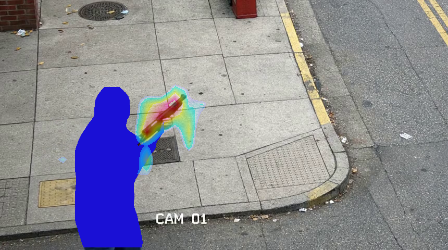

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.3795 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'gun_holding', 'reason': 'A person is holding a firearm on a sidewalk, which is an anomalous activity for public safety.'}
##############################Video Clip Snippet idx 16:32##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 199.83it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 339.18it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 46.12it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.029164 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.076438 seconds.
==============================RESULT==============================


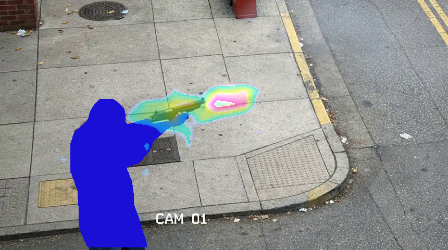

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 
ADXAIVLMInference.inference is done!
process time: 5.4248 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'gun_shooting', 'reason': 'A person is holding and firing a gun on a sidewalk, which is an anomalous activity.'}


In [11]:
xavad_xai_inference(video_filepath, video_frames_anonymized, is_masked_an=True, issave=True)

# XAVAD Inference: cctv_gunman_pistol_shoot_on_public_street

In [12]:
video_filepath = r"../data/Synthetic/cctv_gunman_pistol_shoot_on_public_street_480_860px.mp4"

video_frames, video_meta = util.videofile_loader(video_filepath, start_sec=0, 
                                                 clip_duration=None, 
                                                 fps=fps
                                                )
print("video_meta: ", video_meta)
util.show_video_on_nb(video_frames, video_meta, input_format="BGR", width=480, height=360)

success, video_frames_anonymized = ANObj.inference(video_frames, num_workers=1)
if success:
    util.show_video_on_nb(video_frames_anonymized, video_meta, input_format="BGR", width=480, height=360)

videofile_loader...


process time: 0.33604 seconds.
loaded frame duration: 8.04 secs, frame length: 41, fps: 5, resolution: (480, 860, 3)
video_meta:  {'num_frames': 41, 'fps': 5, 'duration': 8.04, 'frame_size': (480, 860, 3)}


ANInference.inference: 
Processing ANInference.inference: 


ANInference.inference is done!
process time: 0.84583 seconds.


##############################Video Clip Snippet idx 0:16##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 236.84it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 33.95it/s]


...

100%|██████████| 1/1 [00:00<00:00, 246.42it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 45.82it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.036047 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.10589 seconds.
==============================RESULT==============================


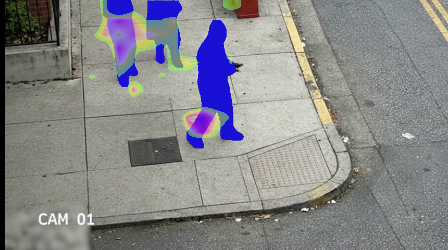

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.7008 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'knife_holding', 'reason': 'A person is holding an object resembling a knife in a confrontational stance on a sidewalk, while two other individuals stand nearby.'}
##############################Video Clip Snippet idx 16:32##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 161.35it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.19158 seconds.
==============================RESULT==============================
{'vandalism': 0.30686, 'normal_activity': 0.2177, 'gun_holding': 0.18559}
pred_anml_category: vandalism, pred_anml_category_idx: 13, condidate_localized_frame_idx: 0
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (250, 448, 3)
xai_cat_name: vandalism, xai_class_idx: 13
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (250, 448, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 290.04it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 44.82it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.030061 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.072867 seconds.
==============================RESULT==============================


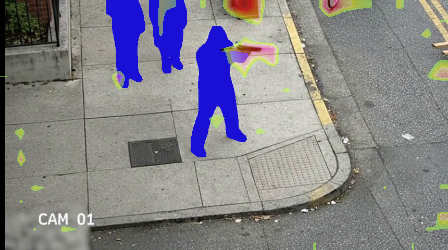

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 
ADXAIVLMInference.inference is done!
process time: 5.6285 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'gun_shooting', 'reason': 'A person is pointing a gun on a sidewalk, with two other individuals nearby. This suggests a potential threat or criminal activity.'}


In [13]:
xavad_xai_inference(video_filepath, video_frames_anonymized, is_masked_an=True, issave=True)

# XAVAD Inference: cctv_fight_with_knife_demo

In [14]:
video_filepath = r"../data/Synthetic/cctv_fight_with_knife_demo_480_860px.mp4"

video_frames, video_meta = util.videofile_loader(video_filepath, start_sec=0, 
                                                 clip_duration=None, 
                                                 fps=fps
                                                )
print("video_meta: ", video_meta)
util.show_video_on_nb(video_frames, video_meta, input_format="BGR", width=480, height=360)

success, video_frames_anonymized = ANObj.inference(video_frames, num_workers=1)
if success:
    util.show_video_on_nb(video_frames_anonymized, video_meta, input_format="BGR", width=480, height=360)

videofile_loader...


process time: 0.29695 seconds.
loaded frame duration: 8.04 secs, frame length: 41, fps: 5, resolution: (480, 860, 3)
video_meta:  {'num_frames': 41, 'fps': 5, 'duration': 8.04, 'frame_size': (480, 860, 3)}


ANInference.inference: 
Processing ANInference.inference: 


ANInference.inference is done!
process time: 0.80521 seconds.


##############################Video Clip Snippet idx 0:16##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 214.74it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 34.09it/s]


...

100%|██████████| 1/1 [00:00<00:00, 328.04it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 48.39it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.03058 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.074202 seconds.
==============================RESULT==============================


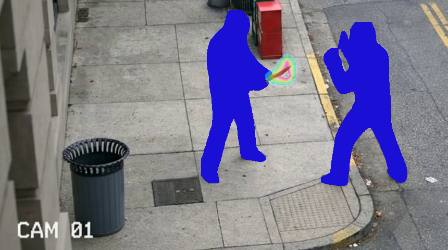

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.3232 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'violence', 'reason': 'Two individuals appear to be engaged in a physical altercation on the sidewalk, with one person holding an object that resembles a weapon.'}
##############################Video Clip Snippet idx 16:32##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 200.32it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 333.41it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 46.89it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.031873 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.073046 seconds.
==============================RESULT==============================


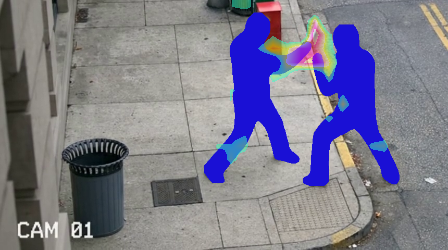

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 
ADXAIVLMInference.inference is done!
process time: 5.5133 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'violence', 'reason': 'Two individuals are engaged in a physical altercation on the sidewalk, with one person appearing to strike the other. The scene suggests a violent confrontation.'}


In [15]:
xavad_xai_inference(video_filepath, video_frames_anonymized, is_masked_an=True, issave=True)

# XAVAD Inference: cctv_person_falling_on_street

In [16]:
video_filepath = r"../data/Synthetic/cctv_person_falling_on_street_480_860px.mp4"

video_frames, video_meta = util.videofile_loader(video_filepath, start_sec=0, 
                                                 clip_duration=None, 
                                                 fps=fps
                                                )
print("video_meta: ", video_meta)
util.show_video_on_nb(video_frames, video_meta, input_format="BGR", width=480, height=360)

success, video_frames_anonymized = ANObj.inference(video_frames, num_workers=1)
if success:
    util.show_video_on_nb(video_frames_anonymized, video_meta, input_format="BGR", width=480, height=360)

videofile_loader...


process time: 0.26879 seconds.
loaded frame duration: 8.04 secs, frame length: 41, fps: 5, resolution: (480, 860, 3)
video_meta:  {'num_frames': 41, 'fps': 5, 'duration': 8.04, 'frame_size': (480, 860, 3)}


ANInference.inference: 
Processing ANInference.inference: 


ANInference.inference is done!
process time: 0.82782 seconds.


##############################Video Clip Snippet idx 0:16##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 57.74it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 33.03it/s]


Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.35661 seconds.
==============================RESULT==============================
{'vandalism': 0.57534, 'normal_activity': 0.22393, 'person falling': 0.09689}
pred_anml_category: vandalism, pred_anml_category_idx: 13, condidate_localized_frame_idx: 12
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (250, 448, 3)
xai_cat_name: vandalism, xai_class_idx: 13
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (250, 448, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 258.91it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 41.95it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.031953 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.080389 seconds.
==============================RESULT==============================


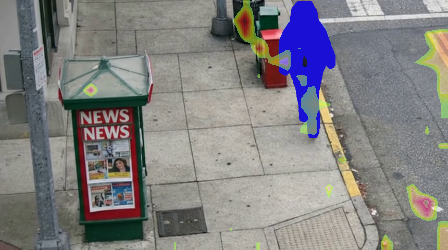

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 2.6014 seconds.
==============================RESULT==============================
{'anomaly_status': 'NO', 'category': 'NORMAL', 'reason': 'The video shows a typical street scene with a newsstand, trash bins, and a pedestrian walking by. There are no visible signs of abnormal activity or events.'}
##############################Video Clip Snippet idx 16:32##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 208.83it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.18749 seconds.
==============================RESULT==============================
{'person falling': 0.47211, 'normal_activity': 0.18844, 'vandalism': 0.15152}
pred_anml_category: person falling, pred_anml_category_idx: 11, condidate_localized_frame_idx: 14
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (250, 448, 3)
xai_cat_name: person falling, xai_class_idx: 11
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (250, 448, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 307.46it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 44.62it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.030639 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.076329 seconds.
==============================RESULT==============================


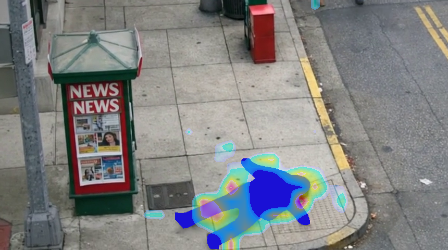

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 
ADXAIVLMInference.inference is done!
process time: 2.4217 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'person_falling', 'reason': 'A person is seen walking on the sidewalk and then falls to the ground. The fall appears unexpected and could indicate a potential safety concern.'}


In [17]:
xavad_xai_inference(video_filepath, video_frames_anonymized, is_masked_an=True, issave=True)